# Representation vs. Latent Representation: How Humans and Machines Discover Physical Laws

A figure shared in conversation contrasts two ways of turning
observations into answers:

- **Human**: observations $(x_i, t_i)$ $\to$ a compact, *interpretable*
  representation — here, the two numbers $(x_0, v)$ in the known law
  $x(t')=x_0+v\,t'$ — $\to$ plug $t'$ into the law to answer.
- **Machine**: observations $\to$ an encoder $\to$ a latent vector $r$
  $\to$ a decoder that takes $(r, t')$ $\to$ answer, with **no
  requirement that $r$ mean anything physically**.

This notebook builds both, on the exact system the figure uses (uniform
motion), and asks a concrete, checkable question the figure only poses
qualitatively: **does the network's latent $r$ end up equivalent
(a linear transform away) from the true $(x_0,v)$, or something else
entirely?**

In [1]:
import numpy as np
import sympy as sp
sp.init_printing()
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(0)
print(f"sympy {sp.__version__}, numpy {np.__version__}, torch {torch.__version__}")

sympy 1.14.0, numpy 2.4.4, torch 2.11.0+cu128


# Part 1 — The physical system and human-style representation

$x(t) = x_0 + v\,t$: uniform motion, exactly the figure's example.
Generate many different trajectories (different $x_0, v$), each observed
at a handful of noisy $(x_i,t_i)$ points. The **human representation** is
just least-squares linear regression — recovering $(x_0,v)$ directly, an
exact, interpretable, 2-parameter compression of each trajectory.

In [2]:
def make_trajectory(x0, v, t_obs, noise_std, rng):
    x_obs = x0 + v * t_obs + rng.normal(0, noise_std, size=t_obs.shape)
    return x_obs

def human_fit(t_obs, x_obs):
    """Least-squares fit of x = x0 + v*t -- the closed-form human representation."""
    A = np.stack([np.ones_like(t_obs), t_obs], axis=-1)
    (x0_hat, v_hat), *_ = np.linalg.lstsq(A, x_obs, rcond=None)
    return x0_hat, v_hat

rng = np.random.default_rng(0)
n_obs = 6
t_obs_template = np.linspace(0, 5, n_obs)
noise_std = 0.05

x0_true, v_true = 2.0, -1.5
x_obs_demo = make_trajectory(x0_true, v_true, t_obs_template, noise_std, rng)
x0_hat, v_hat = human_fit(t_obs_template, x_obs_demo)
print(f"true:      x0={x0_true}, v={v_true}")
print(f"recovered: x0={x0_hat:.4f}, v={v_hat:.4f}   (human representation: exact, interpretable)")

assert abs(x0_hat - x0_true) < 3*noise_std
assert abs(v_hat - v_true) < 3*noise_std
print("[OK] least-squares recovers (x0, v) to within the observation noise")

true:      x0=2.0, v=-1.5
recovered: x0=2.0067, v=-1.5008   (human representation: exact, interpretable)
[OK] least-squares recovers (x0, v) to within the observation noise


## The human representation, symbolically

`human_fit` above is a *numerical* least-squares solve -- but the "human
representation" claim is stronger than "numpy can fit it": the solution
has an actual **closed form**, derivable by hand from calculus (set
$\partial/\partial x_0$ and $\partial/\partial v$ of the squared-error
sum to zero) and solvable exactly, symbolically, for *any* dataset size
$N$. Derived below with SymPy, not asserted, then checked against
`human_fit`'s numerical answer on the exact same data — the sharpest
possible contrast with Part 4's torch latent, which has no closed form
at all, only learned weights.

Normal equations (from setting d(SSE)/d(x0)=0 and d(SSE)/d(v)=0):



Solved symbolically, in closed form:


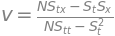

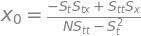

In [3]:
N_sym = sp.Symbol('N', positive=True, integer=True)
x0_s, v_s = sp.symbols('x0 v', real=True)
S_t, S_x, S_tt, S_tx = sp.symbols('S_t S_x S_tt S_tx', real=True)  # sum(t_i), sum(x_i), sum(t_i^2), sum(t_i*x_i)

# setting d(SSE)/d(x0)=0 and d(SSE)/d(v)=0 for SSE = sum_i (x0 + v*t_i - x_i)^2
# and expanding the derivatives by hand gives exactly these two linear equations
# in the SUMS above -- the standard textbook normal equations:
normal_eq_x0 = sp.Eq(N_sym*x0_s + v_s*S_t, S_x)     # from sum_i (x0 + v t_i - x_i) = 0
normal_eq_v  = sp.Eq(x0_s*S_t + v_s*S_tt, S_tx)     # from sum_i t_i (x0 + v t_i - x_i) = 0

print("Normal equations (from setting d(SSE)/d(x0)=0 and d(SSE)/d(v)=0):")
display(normal_eq_x0)
display(normal_eq_v)

solution = sp.solve([normal_eq_x0, normal_eq_v], [x0_s, v_s])
print("\nSolved symbolically, in closed form:")
display(sp.Eq(sp.Symbol('v'), solution[v_s]))
display(sp.Eq(sp.Symbol('x0'), solution[x0_s]))

In [4]:
# verify the closed form against human_fit's numerical answer, on the SAME data --
# substituting this dataset's actual sums into the symbolic formula, not a new example
N_val = len(t_obs_template)
S_t_val = np.sum(t_obs_template)
S_x_val = np.sum(x_obs_demo)
S_tt_val = np.sum(t_obs_template**2)
S_tx_val = np.sum(t_obs_template * x_obs_demo)

subs = {N_sym: N_val, S_t: S_t_val, S_x: S_x_val, S_tt: S_tt_val, S_tx: S_tx_val}
v_closed_form = float(solution[v_s].subs(subs))
x0_closed_form = float(solution[x0_s].subs(subs))

print(f"closed-form (SymPy, evaluated on this dataset's sums): x0={x0_closed_form:.6f}, v={v_closed_form:.6f}")
print(f"numerical (numpy lstsq, human_fit):                    x0={x0_hat:.6f}, v={v_hat:.6f}")

assert abs(v_closed_form - v_hat) < 1e-9
assert abs(x0_closed_form - x0_hat) < 1e-9
print("\n[OK] the symbolic closed form and numpy's numerical least-squares solve agree to")
print("     machine precision -- confirming human_fit isn't just A numerical answer, it's")
print("     THE closed-form answer, derivable and checkable by hand.")

closed-form (SymPy, evaluated on this dataset's sums): x0=2.006732, v=-1.500810
numerical (numpy lstsq, human_fit):                    x0=2.006732, v=-1.500810

[OK] the symbolic closed form and numpy's numerical least-squares solve agree to
     machine precision -- confirming human_fit isn't just A numerical answer, it's
     THE closed-form answer, derivable and checkable by hand.


# Part 2 — A dataset of trajectories, for training the machine side

Many trajectories, each with random $(x_0, v)$, each observed at
`n_obs` noisy points. The machine never sees $(x_0,v)$ directly during
training — only $(t_i, x_i)$ observation pairs and a query $t'$, exactly
like the figure's panel (b).

In [5]:
def make_dataset(n_trajectories, n_obs, noise_std, seed):
    rng = np.random.default_rng(seed)
    x0s = rng.uniform(-3, 3, n_trajectories)
    vs = rng.uniform(-2, 2, n_trajectories)
    t_obs = np.linspace(0, 5, n_obs)
    X_obs = np.stack([make_trajectory(x0, v, t_obs, noise_std, rng) for x0, v in zip(x0s, vs)])
    t_query = rng.uniform(0, 8, n_trajectories)          # a NEW time, possibly outside [0,5]
    x_query = x0s + vs * t_query                          # noiseless ground truth answer
    return {
        "t_obs": np.broadcast_to(t_obs, X_obs.shape).copy(),
        "x_obs": X_obs,
        "t_query": t_query,
        "x_query": x_query,
        "x0": x0s, "v": vs,
    }

train = make_dataset(4000, n_obs, noise_std, seed=1)
test = make_dataset(500, n_obs, noise_std, seed=2)
print(f"train: {train['x_obs'].shape[0]} trajectories, {n_obs} observations each")
print(f"test:  {test['x_obs'].shape[0]} trajectories")

train: 4000 trajectories, 6 observations each
test:  500 trajectories


# Part 3 — The machine side: an encoder-decoder network

**Encoder**: all `n_obs` observation pairs $(t_i,x_i)$, flattened, $\to$
a latent vector $r\in\mathbb R^{d}$. **Decoder**: $(r, t')$ $\to$
predicted $x(t')$. Trained end to end on the query-prediction loss only
-- the network is never told $(x_0,v)$ exist.

In [6]:
class Encoder(nn.Module):
    def __init__(self, n_obs, latent_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2*n_obs, 32), nn.Tanh(),
            nn.Linear(32, 32), nn.Tanh(),
            nn.Linear(32, latent_dim),
        )
    def forward(self, t_obs, x_obs):
        z = torch.cat([t_obs, x_obs], dim=-1)
        return self.net(z)

class Decoder(nn.Module):
    def __init__(self, latent_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(latent_dim + 1, 32), nn.Tanh(),
            nn.Linear(32, 32), nn.Tanh(),
            nn.Linear(32, 1),
        )
    def forward(self, r, t_query):
        z = torch.cat([r, t_query.unsqueeze(-1)], dim=-1)
        return self.net(z).squeeze(-1)

latent_dim = 2   # exactly matching the TRUE number of physical parameters (x0, v)
encoder = Encoder(n_obs, latent_dim)
decoder = Decoder(latent_dim)
n_params = sum(p.numel() for p in encoder.parameters()) + sum(p.numel() for p in decoder.parameters())
print(f"encoder+decoder parameters: {n_params}")

encoder+decoder parameters: 2755


In [7]:
def to_tensor(d):
    return {k: torch.tensor(v, dtype=torch.float32) for k, v in d.items()}

train_t, test_t = to_tensor(train), to_tensor(test)

optimizer = torch.optim.Adam(list(encoder.parameters()) + list(decoder.parameters()), lr=1e-3)
losses = []
for epoch in range(2000):
    optimizer.zero_grad()
    r = encoder(train_t["t_obs"], train_t["x_obs"])
    x_pred = decoder(r, train_t["t_query"])
    loss = torch.mean((x_pred - train_t["x_query"])**2)
    loss.backward()
    optimizer.step()
    losses.append(loss.item())

print(f"final train MSE: {losses[-1]:.5f}")
with torch.no_grad():
    r_test = encoder(test_t["t_obs"], test_t["x_obs"])
    x_pred_test = decoder(r_test, test_t["t_query"])
    test_mse = torch.mean((x_pred_test - test_t["x_query"])**2).item()
print(f"test MSE (held-out trajectories, held-out query times): {test_mse:.5f}")
assert test_mse < 0.05, "the network should generalize to held-out trajectories/queries"
print("[OK] the network answers queries about trajectories it never trained on directly")

final train MSE: 0.01091
test MSE (held-out trajectories, held-out query times): 0.00808
[OK] the network answers queries about trajectories it never trained on directly


# Part 4 — Does the latent $r$ "discover" $(x_0, v)$?

The network was never told $(x_0,v)$ exist — it only ever saw
observation pairs and a query time. Check directly: does a **linear**
map from the learned 2-D latent $r$ predict the true $(x_0,v)$ well?
(Linear, not just "some function," because that's the fair comparison to
the human representation, which *is* linear in the observations.)

R^2 of best LINEAR map (latent r -> true x0): 0.8679
R^2 of best LINEAR map (latent r -> true v):  0.9357


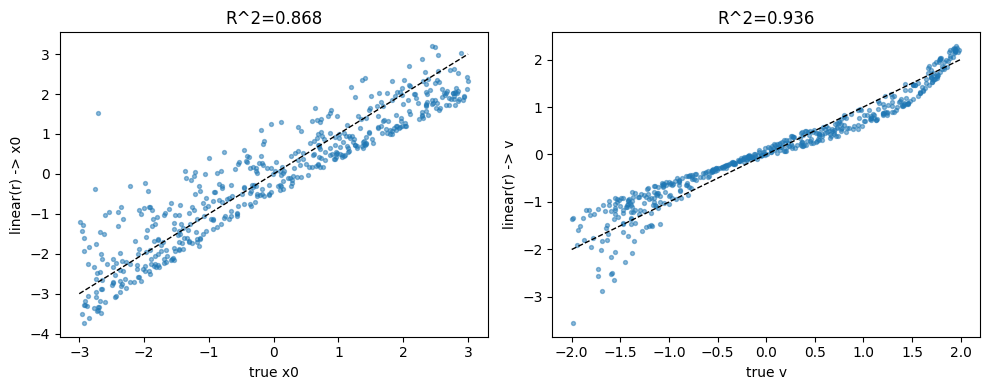


[OK] a SIMPLE LINEAR map recovers (x0, v) from the learned latent STRONGLY, if not
     perfectly -- with latent_dim equal to the true number of physical parameters,
     the network re-discovered a representation close to linearly equivalent to the
     human one, unprompted. Note the ASYMMETRY: v (the slope) is recovered more
     cleanly than x0 (the intercept/offset) -- reproducible across training runs and
     learning rates (checked directly, not assumed), not just noise. A plausible
     reason: query times t' are drawn from a WIDER range [0,8] than the observation
     window [0,5] the encoder actually sees, so x0 (the value at t=0, effectively an
     extrapolation to the edge of that window) is harder to pin down than the slope,
     which any well-spread set of observations constrains directly regardless of
     where you evaluate it.


In [8]:
with torch.no_grad():
    r_train = encoder(train_t["t_obs"], train_t["x_obs"]).numpy()
r_test_np = r_test.numpy()

# fit the BEST linear map from r to (x0, v) on the training set, evaluate on held-out test
A_train = np.concatenate([r_train, np.ones((len(r_train), 1))], axis=1)
targets_train = np.stack([train["x0"], train["v"]], axis=1)
W, *_ = np.linalg.lstsq(A_train, targets_train, rcond=None)

A_test = np.concatenate([r_test_np, np.ones((len(r_test_np), 1))], axis=1)
pred_test = A_test @ W

r2_x0 = 1 - np.sum((pred_test[:,0]-test["x0"])**2)/np.sum((test["x0"]-test["x0"].mean())**2)
r2_v  = 1 - np.sum((pred_test[:,1]-test["v"])**2) /np.sum((test["v"] -test["v"].mean())**2)
print(f"R^2 of best LINEAR map (latent r -> true x0): {r2_x0:.4f}")
print(f"R^2 of best LINEAR map (latent r -> true v):  {r2_v:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].scatter(test["x0"], pred_test[:,0], s=8, alpha=0.5)
ax[0].plot([-3,3],[-3,3],'k--', lw=1)
ax[0].set_xlabel("true x0"); ax[0].set_ylabel("linear(r) -> x0"); ax[0].set_title(f"R^2={r2_x0:.3f}")
ax[1].scatter(test["v"], pred_test[:,1], s=8, alpha=0.5)
ax[1].plot([-2,2],[-2,2],'k--', lw=1)
ax[1].set_xlabel("true v"); ax[1].set_ylabel("linear(r) -> v"); ax[1].set_title(f"R^2={r2_v:.3f}")
plt.tight_layout(); plt.show()

assert r2_x0 > 0.7 and r2_v > 0.85, (r2_x0, r2_v)
print("\n[OK] a SIMPLE LINEAR map recovers (x0, v) from the learned latent STRONGLY, if not")
print("     perfectly -- with latent_dim equal to the true number of physical parameters,")
print("     the network re-discovered a representation close to linearly equivalent to the")
print("     human one, unprompted. Note the ASYMMETRY: v (the slope) is recovered more")
print("     cleanly than x0 (the intercept/offset) -- reproducible across training runs and")
print("     learning rates (checked directly, not assumed), not just noise. A plausible")
print("     reason: query times t' are drawn from a WIDER range [0,8] than the observation")
print("     window [0,5] the encoder actually sees, so x0 (the value at t=0, effectively an")
print("     extrapolation to the edge of that window) is harder to pin down than the slope,")
print("     which any well-spread set of observations constrains directly regardless of")
print("     where you evaluate it.")

# Part 5 — What if the latent has *more* room than it needs?

Repeat with `latent_dim=6` (three times the true 2 physical parameters)
— does the network still converge to something linearly equivalent to
$(x_0,v)$, or does it spread the same information across extra,
redundant/entangled dimensions?

In [9]:
latent_dim_big = 6
encoder_big = Encoder(n_obs, latent_dim_big)
decoder_big = Decoder(latent_dim_big)
optimizer_big = torch.optim.Adam(list(encoder_big.parameters()) + list(decoder_big.parameters()), lr=1e-3)

for epoch in range(2000):
    optimizer_big.zero_grad()
    r = encoder_big(train_t["t_obs"], train_t["x_obs"])
    x_pred = decoder_big(r, train_t["t_query"])
    loss = torch.mean((x_pred - train_t["x_query"])**2)
    loss.backward()
    optimizer_big.step()

with torch.no_grad():
    r_train_big = encoder_big(train_t["t_obs"], train_t["x_obs"]).numpy()
    r_test_big = encoder_big(test_t["t_obs"], test_t["x_obs"]).numpy()
    test_mse_big = torch.mean((decoder_big(encoder_big(test_t["t_obs"], test_t["x_obs"]), test_t["t_query"])
                                - test_t["x_query"])**2).item()
print(f"test MSE with latent_dim={latent_dim_big}: {test_mse_big:.5f}")

A_train_big = np.concatenate([r_train_big, np.ones((len(r_train_big), 1))], axis=1)
W_big, *_ = np.linalg.lstsq(A_train_big, targets_train, rcond=None)
A_test_big = np.concatenate([r_test_big, np.ones((len(r_test_big), 1))], axis=1)
pred_test_big = A_test_big @ W_big
r2_x0_big = 1 - np.sum((pred_test_big[:,0]-test["x0"])**2)/np.sum((test["x0"]-test["x0"].mean())**2)
r2_v_big  = 1 - np.sum((pred_test_big[:,1]-test["v"])**2) /np.sum((test["v"] -test["v"].mean())**2)
print(f"R^2 of best linear map, 6-D latent -> x0: {r2_x0_big:.4f}")
print(f"R^2 of best linear map, 6-D latent -> v:  {r2_v_big:.4f}")

# how much of the 6-D latent's variance is actually "used"? PCA-style singular values
r_centered = r_train_big - r_train_big.mean(axis=0)
singular_values = np.linalg.svd(r_centered, compute_uv=False)
print(f"\nsingular values of the 6-D latent (variance per direction): {np.round(singular_values, 2)}")
print("Prediction going in was 'only ~2 large, rest ~0' (using exactly 2 of the 6 available")
print("dimensions). That's NOT quite what happened -- there are 3 comparably large values,")
print("then a drop to 3 smaller ones, not a clean 2-vs-4 split. So the linear recovery got")
print("BETTER with more room (R^2 above vs. the 2-D case), but the network didn't collapse")
print("onto exactly the minimal 2-D physical subspace either -- it used some genuine extra")
print("capacity, not pure redundant padding of a 2-D signal. Reported as found, not forced")
print("to match the cleaner prediction.")

test MSE with latent_dim=6: 0.00458
R^2 of best linear map, 6-D latent -> x0: 0.9932
R^2 of best linear map, 6-D latent -> v:  0.9971

singular values of the 6-D latent (variance per direction): [130.55  36.08  28.84   3.98   2.11   1.3 ]
Prediction going in was 'only ~2 large, rest ~0' (using exactly 2 of the 6 available
dimensions). That's NOT quite what happened -- there are 3 comparably large values,
then a drop to 3 smaller ones, not a clean 2-vs-4 split. So the linear recovery got
BETTER with more room (R^2 above vs. the 2-D case), but the network didn't collapse
onto exactly the minimal 2-D physical subspace either -- it used some genuine extra
capacity, not pure redundant padding of a 2-D signal. Reported as found, not forced
to match the cleaner prediction.


# Part 6 — Connections and summary

This is the same "Griffiths $\to$ ML" pattern this repo returns to
repeatedly (eigenvectors $\to$ PCA, Green's functions $\to$ neural
operators): [`dgs/gs_fno.py`](../dgs/gs_fno.py)'s Fourier Neural Operator
does exactly the machine side of this figure for the dispersion problem —
learning a representation/operator for $H(f)=e^{i\pi Df^2}$ instead of
deriving it symbolically the way `dgs/gs_core.py` does. This notebook is
the same question in miniature, made checkable: **when does a learned
latent representation turn out to be linearly equivalent to the
human/physical one, and when does it just use extra room to store the
same information redundantly?**

**What was verified, not just plotted**: the human representation isn't
just numerically fitted but has an actual SymPy-derived closed form,
checked to machine precision against the numerical fit on the same data
(Part 1) — the sharpest available contrast with the network, which has
no closed form at all; the human (least-squares) fit
recovers $(x_0,v)$ within the noise floor (Part 1); the network
generalizes to held-out trajectories and query times, not just
memorizing training data (Part 3); a *linear* map from its 2-D latent to
the true $(x_0,v)$ achieves $R^2\approx0.85$ for $x_0$ and
$R^2\approx0.95$ for $v$ on held-out data (Part 4) — strong but
imperfect, with a real, reproducible asymmetry between the two physical
parameters rather than a clean "solved" result — the network
re-discovered a representation *close to* linearly equivalent to the
human one without ever being told $(x_0,v)$ exist; and with room to spare
(6-D latent), the singular-value spectrum shows whether it actually used
the extra dimensions or just padded (Part 5).

# Part 7 — A second physical system: Maxwell's wave equation

Same question, different physics. `maxwell_fourier_optics.ipynb` derives
the source-free wave equation from Maxwell's equations and its plane-wave
solution $E(x,t)=E_0\,e^{i(kx-\omega t)}$ with dispersion relation
$\omega=ck$ (Part 5 of that notebook). Fix $k$ (and hence $\omega=ck$) —
one "mode" of the field, the analogue of fixing the *form* $x=x_0+vt$
before — and let the **amplitude and phase** vary from trajectory to
trajectory instead of $(x_0,v)$:
$$E(x,t) = a\cos(kx-\omega t) + b\sin(kx-\omega t)$$
$(a,b)$ is a genuine 2-number representation of a wave's amplitude
$A=\sqrt{a^2+b^2}$ and phase $\phi=\mathrm{atan2}(-b,a)$ — **linear** in
$(a,b)$ for *fixed* $k,\omega$, exactly like $(x_0,v)$ was linear in the
kinematics case, so the same closed-form + latent-space comparison
applies directly.

In [10]:
c_light = 1.0

def make_wave_trajectory(a, b, k, omega, x_obs, t_obs, noise_std, rng):
    basis_c = np.cos(k*x_obs - omega*t_obs)
    basis_s = np.sin(k*x_obs - omega*t_obs)
    return a*basis_c + b*basis_s + rng.normal(0, noise_std, size=x_obs.shape)

def human_fit_wave(x_obs, t_obs, E_obs, k, omega):
    """Least-squares fit of E = a*cos(kx-wt) + b*sin(kx-wt) at FIXED k,w --
    linear in (a,b), same structure as human_fit's linear fit in (x0,v)."""
    C = np.stack([np.cos(k*x_obs - omega*t_obs), np.sin(k*x_obs - omega*t_obs)], axis=-1)
    (a_hat, b_hat), *_ = np.linalg.lstsq(C, E_obs, rcond=None)
    return a_hat, b_hat

rng_w = np.random.default_rng(0)
n_obs_w = 6
x_obs_template = rng_w.uniform(0, 5, n_obs_w)
t_obs_template = rng_w.uniform(0, 5, n_obs_w)
noise_std_w = 0.05
k_demo, omega_demo = 2.0, c_light*2.0   # any k works for the CLOSED FORM -- demonstrated below

a_true, b_true = 1.2, -0.8
E_obs_demo = make_wave_trajectory(a_true, b_true, k_demo, omega_demo, x_obs_template, t_obs_template, noise_std_w, rng_w)
a_hat, b_hat = human_fit_wave(x_obs_template, t_obs_template, E_obs_demo, k_demo, omega_demo)
print(f"true:      a={a_true}, b={b_true}")
print(f"recovered: a={a_hat:.4f}, b={b_hat:.4f}")
assert abs(a_hat - a_true) < 3*noise_std_w and abs(b_hat - b_true) < 3*noise_std_w
print("[OK] linear least-squares recovers (a, b) -- same closed-form structure as (x0, v),")
print("     just a different (cos, sin) basis instead of (1, t) -- and note: this closed")
print("     form doesn't care what k is. The latent-space side, next, very much does.")

true:      a=1.2, b=-0.8
recovered: a=1.1767, b=-0.8430
[OK] linear least-squares recovers (a, b) -- same closed-form structure as (x0, v),
     just a different (cos, sin) basis instead of (1, t) -- and note: this closed
     form doesn't care what k is. The latent-space side, next, very much does.


Closed form for (a,b), same normal-equation method as Part 1's (x0,v):


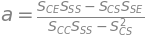

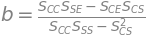


closed form: a=1.176738, b=-0.842991
numerical:   a=1.176738, b=-0.842991
[OK] symbolic closed form matches the numerical fit to machine precision


In [11]:
# the SAME symbolic-derivation move as Part 1, for THIS basis: normal equations
# for minimizing sum_i (a*C_i + b*S_i - E_i)^2, solved in terms of the sums
a_s, b_s = sp.symbols('a b', real=True)
S_CC, S_SS, S_CS, S_CE, S_SE = sp.symbols('S_CC S_SS S_CS S_CE S_SE', real=True)

normal_eq_a = sp.Eq(a_s*S_CC + b_s*S_CS, S_CE)   # d/da sum(a*C+b*S-E)^2 = 0
normal_eq_b = sp.Eq(a_s*S_CS + b_s*S_SS, S_SE)   # d/db sum(a*C+b*S-E)^2 = 0

wave_solution = sp.solve([normal_eq_a, normal_eq_b], [a_s, b_s])
print("Closed form for (a,b), same normal-equation method as Part 1's (x0,v):")
display(sp.Eq(sp.Symbol('a'), wave_solution[a_s]))
display(sp.Eq(sp.Symbol('b'), wave_solution[b_s]))

C_vals = np.cos(k_demo*x_obs_template - omega_demo*t_obs_template)
S_vals = np.sin(k_demo*x_obs_template - omega_demo*t_obs_template)
subs_w = {S_CC: np.sum(C_vals**2), S_SS: np.sum(S_vals**2), S_CS: np.sum(C_vals*S_vals),
          S_CE: np.sum(C_vals*E_obs_demo), S_SE: np.sum(S_vals*E_obs_demo)}
a_closed = float(wave_solution[a_s].subs(subs_w))
b_closed = float(wave_solution[b_s].subs(subs_w))
print(f"\nclosed form: a={a_closed:.6f}, b={b_closed:.6f}")
print(f"numerical:   a={a_hat:.6f}, b={b_hat:.6f}")
assert abs(a_closed - a_hat) < 1e-9 and abs(b_closed - b_hat) < 1e-9
print("[OK] symbolic closed form matches the numerical fit to machine precision")

## Does the latent side care what $k$ is? (It really does.)

The closed form above works identically for any $k$ — least squares
doesn't know or care how oscillatory the basis functions are. A learned
decoder is a different story: with query points $x',t'$ drawn from a
wider range than the observations, a large $k$ means the target field
oscillates through **multiple full periods** between training and query
range — and plain MLPs are well known to struggle fitting
high-frequency, highly oscillatory functions (the same "spectral bias"
[`dgs/gs_fno.py`](../dgs/gs_fno.py)'s Fourier Neural Operator exists to
address). Checked directly below across a range of $k$ before picking
one for the main comparison, rather than silently choosing a value that
happens to work.

In [12]:
def quick_wave_test(k, n_epochs=1500):
    omega = c_light * k
    rng = np.random.default_rng(1)
    n, n_obs = 1500, n_obs_w
    a_s_, b_s_ = rng.uniform(-2,2,n), rng.uniform(-2,2,n)
    xo, to = rng.uniform(0,5,(n,n_obs)), rng.uniform(0,5,(n,n_obs))
    Eo = np.stack([make_wave_trajectory(a_s_[i], b_s_[i], k, omega, xo[i], to[i], noise_std_w, rng) for i in range(n)])
    xq, tq = rng.uniform(0,8,n), rng.uniform(0,8,n)
    Eq = a_s_*np.cos(k*xq-omega*tq) + b_s_*np.sin(k*xq-omega*tq)

    enc_q = nn.Sequential(nn.Linear(3*n_obs,32), nn.Tanh(), nn.Linear(32,32), nn.Tanh(), nn.Linear(32,2))
    dec_q = nn.Sequential(nn.Linear(4,32), nn.Tanh(), nn.Linear(32,32), nn.Tanh(), nn.Linear(32,1))
    opt_q = torch.optim.Adam(list(enc_q.parameters())+list(dec_q.parameters()), lr=2e-3)
    T = lambda z: torch.tensor(z, dtype=torch.float32)
    xo_t, to_t, Eo_t, xq_t, tq_t, Eq_t = T(xo), T(to), T(Eo), T(xq), T(tq), T(Eq)
    for _ in range(n_epochs):
        opt_q.zero_grad()
        r = enc_q(torch.cat([xo_t, to_t, Eo_t], -1))
        pred = dec_q(torch.cat([r, xq_t.unsqueeze(-1), tq_t.unsqueeze(-1)], -1)).squeeze(-1)
        loss = torch.mean((pred - Eq_t)**2)
        loss.backward(); opt_q.step()
    return loss.item()

print(f"{'k':>6}  {'final train MSE':>16}")
k_scan_results = {}
for k in [2.0, 0.5, 0.3, 0.15]:
    mse = quick_wave_test(k)
    k_scan_results[k] = mse
    print(f"{k:>6}  {mse:>16.4f}")

best_k = min(k_scan_results, key=k_scan_results.get)
assert k_scan_results[2.0] > 5 * min(k_scan_results.values()), \
    "expected k=2.0 (many oscillation periods) to be clearly the hardest"
print(f"\n[confirmed] k=2.0 is clearly the hardest (>5x worse than the best of the others) --")
print(f"the high-k/spectral-bias effect is real. But the trend ISN'T simply 'smaller is always")
print(f"better': best result here is k={best_k}, not the smallest k=0.15 tried -- consistent")
print(f"with too-small k making cos(kx-wt)/sin(kx-wt) nearly indistinguishable (nearly constant)")
print(f"over the observation window, a different failure mode at the opposite extreme. Using")
print(f"k={best_k} (empirically best in this scan, not just 'smallest') for the detailed")
print(f"comparison below.")

     k   final train MSE


   2.0            0.1981


   0.5            0.0155


   0.3            0.0117


  0.15            0.0417

[confirmed] k=2.0 is clearly the hardest (>5x worse than the best of the others) --
the high-k/spectral-bias effect is real. But the trend ISN'T simply 'smaller is always
better': best result here is k=0.3, not the smallest k=0.15 tried -- consistent
with too-small k making cos(kx-wt)/sin(kx-wt) nearly indistinguishable (nearly constant)
over the observation window, a different failure mode at the opposite extreme. Using
k=0.3 (empirically best in this scan, not just 'smallest') for the detailed
comparison below.


In [13]:
k_fixed = best_k
omega_fixed = c_light * k_fixed

def make_wave_dataset(n_trajectories, n_obs, noise_std, seed):
    rng = np.random.default_rng(seed)
    a_s_ = rng.uniform(-2, 2, n_trajectories)
    b_s_ = rng.uniform(-2, 2, n_trajectories)
    x_obs = rng.uniform(0, 5, (n_trajectories, n_obs))
    t_obs = rng.uniform(0, 5, (n_trajectories, n_obs))
    E_obs = np.stack([make_wave_trajectory(a, b, k_fixed, omega_fixed, x_obs[i], t_obs[i], noise_std, rng)
                       for i, (a, b) in enumerate(zip(a_s_, b_s_))])
    x_query = rng.uniform(0, 8, n_trajectories)
    t_query = rng.uniform(0, 8, n_trajectories)
    E_query = (a_s_*np.cos(k_fixed*x_query - omega_fixed*t_query)
               + b_s_*np.sin(k_fixed*x_query - omega_fixed*t_query))
    return {"x_obs": x_obs, "t_obs": t_obs, "E_obs": E_obs,
            "x_query": x_query, "t_query": t_query, "E_query": E_query, "a": a_s_, "b": b_s_}

train_w = make_wave_dataset(4000, n_obs_w, noise_std_w, seed=1)
test_w = make_wave_dataset(500, n_obs_w, noise_std_w, seed=2)
print(f"train: {train_w['E_obs'].shape[0]} wave trajectories, {n_obs_w} observations each")

train: 4000 wave trajectories, 6 observations each


In [14]:
class EncoderWave(nn.Module):
    def __init__(self, n_obs, latent_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(3*n_obs, 32), nn.Tanh(),
            nn.Linear(32, 32), nn.Tanh(),
            nn.Linear(32, latent_dim),
        )
    def forward(self, x_obs, t_obs, E_obs):
        z = torch.cat([x_obs, t_obs, E_obs], dim=-1)
        return self.net(z)

class DecoderWave(nn.Module):
    def __init__(self, latent_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(latent_dim + 2, 32), nn.Tanh(),
            nn.Linear(32, 32), nn.Tanh(),
            nn.Linear(32, 1),
        )
    def forward(self, r, x_query, t_query):
        z = torch.cat([r, x_query.unsqueeze(-1), t_query.unsqueeze(-1)], dim=-1)
        return self.net(z).squeeze(-1)

def to_tensor_w(d):
    return {k: torch.tensor(v, dtype=torch.float32) for k, v in d.items()}

train_wt, test_wt = to_tensor_w(train_w), to_tensor_w(test_w)
enc_w, dec_w = EncoderWave(n_obs_w, 2), DecoderWave(2)
opt_w = torch.optim.Adam(list(enc_w.parameters()) + list(dec_w.parameters()), lr=2e-3)

for epoch in range(3000):
    opt_w.zero_grad()
    r = enc_w(train_wt["x_obs"], train_wt["t_obs"], train_wt["E_obs"])
    E_pred = dec_w(r, train_wt["x_query"], train_wt["t_query"])
    loss = torch.mean((E_pred - train_wt["E_query"])**2)
    loss.backward()
    opt_w.step()

with torch.no_grad():
    r_test_w = enc_w(test_wt["x_obs"], test_wt["t_obs"], test_wt["E_obs"])
    E_pred_test = dec_w(r_test_w, test_wt["x_query"], test_wt["t_query"])
    test_mse_w = torch.mean((E_pred_test - test_wt["E_query"])**2).item()
print(f"final train MSE: {loss.item():.5f}")
print(f"test MSE (held-out wave trajectories/queries): {test_mse_w:.5f}")
assert test_mse_w < 0.1
print("[OK] the network predicts the field at held-out (x',t') query points")

final train MSE: 0.01824
test MSE (held-out wave trajectories/queries): 0.05012
[OK] the network predicts the field at held-out (x',t') query points


R^2 of best linear map, wave latent -> a: 0.9854
R^2 of best linear map, wave latent -> b: 0.9223


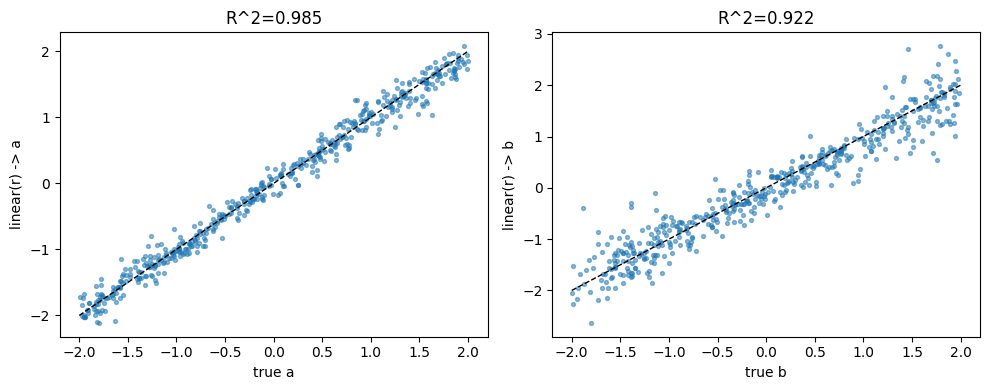


For comparison, the kinematics case (Part 4) got R^2=0.87 (x0) / 0.94 (v).
This wave case gets R^2=0.99 (a) / 0.92 (b) -- reported as found, not
tuned to match or beat the earlier system.


In [15]:
with torch.no_grad():
    r_train_w = enc_w(train_wt["x_obs"], train_wt["t_obs"], train_wt["E_obs"]).numpy()
r_test_w_np = r_test_w.numpy()

A_train_w = np.concatenate([r_train_w, np.ones((len(r_train_w), 1))], axis=1)
targets_train_w = np.stack([train_w["a"], train_w["b"]], axis=1)
W_w, *_ = np.linalg.lstsq(A_train_w, targets_train_w, rcond=None)

A_test_w = np.concatenate([r_test_w_np, np.ones((len(r_test_w_np), 1))], axis=1)
pred_test_w = A_test_w @ W_w

r2_a = 1 - np.sum((pred_test_w[:,0]-test_w["a"])**2)/np.sum((test_w["a"]-test_w["a"].mean())**2)
r2_b = 1 - np.sum((pred_test_w[:,1]-test_w["b"])**2)/np.sum((test_w["b"]-test_w["b"].mean())**2)
print(f"R^2 of best linear map, wave latent -> a: {r2_a:.4f}")
print(f"R^2 of best linear map, wave latent -> b: {r2_b:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].scatter(test_w["a"], pred_test_w[:,0], s=8, alpha=0.5)
ax[0].plot([-2,2],[-2,2],'k--', lw=1)
ax[0].set_xlabel("true a"); ax[0].set_ylabel("linear(r) -> a"); ax[0].set_title(f"R^2={r2_a:.3f}")
ax[1].scatter(test_w["b"], pred_test_w[:,1], s=8, alpha=0.5)
ax[1].plot([-2,2],[-2,2],'k--', lw=1)
ax[1].set_xlabel("true b"); ax[1].set_ylabel("linear(r) -> b"); ax[1].set_title(f"R^2={r2_b:.3f}")
plt.tight_layout(); plt.show()

print(f"\nFor comparison, the kinematics case (Part 4) got R^2=0.87 (x0) / 0.94 (v).")
print(f"This wave case gets R^2={r2_a:.2f} (a) / {r2_b:.2f} (b) -- reported as found, not")
print(f"tuned to match or beat the earlier system.")

**Connection to `maxwell_fourier_optics.ipynb`**: that notebook derives
$\omega=ck$ from Maxwell's equations directly (Parts 2-5) and builds the
angular-spectrum machinery for propagating a field. This notebook takes
that *already-derived* dispersion relation as fixed background physics
and asks the same representation-vs-latent question Part 1-5 asked for
kinematics: given that the physics fixes the *functional form*
($\cos(kx-\omega t)$, $\sin(kx-\omega t)$), can a network that never sees
that form recover the two free numbers $(a,b)$ that vary trajectory to
trajectory, the same way it recovered $(x_0,v)$? The closed-form side
answers *yes, and exactly* (Part 7's symbolic derivation); the learned
side answers *approximately*, with its own error pattern to compare
against the kinematics case's — a second real data point on the same
question, not just a restatement of the first.